# Кредитный риск: обучение, MLflow и контейнеризация
Привалов Максим Александрович, МПИ-25-1-1. Контрольная №1 по MLOps, задания 46–49.

В ДЗ 1.1 прогнозировался дефолт по транзакциям Alfa-Battle с помощью LogisticRegression и CatBoost. Здесь продолжается та же задача кредитного риска, но используется [Default of Credit Card Clients с Kaggle](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset), поскольку в №46 указан Kaggle. Это другая выборка: готовые месячные показатели карточных клиентов, а не сырые транзакции Alfa-Battle. Метрики двух работ напрямую не сравниваются.

Цель `default.payment.next.month`: 1 — дефолт в следующем месяце, 0 — его отсутствие. Данные: I-Cheng Yeh, UCI, [DOI 10.24432/C55S3H](https://doi.org/10.24432/C55S3H), CC BY 4.0. Это историческая учебная выборка Тайваня; оценка на ней не подтверждает качество на современных клиентах другого банка.

Все загрузка, подготовка, обучение и логирование находятся в этом ноутбуке. Python 3.10; основные версии библиотек указаны ниже. Отдельный `app.py` реализует только API для задания 47.

In [1]:
from pathlib import Path
from importlib.metadata import version
import io, json, hashlib, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, mlflow, mlflow.sklearn, mlflow.catboost
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss, precision_recall_curve, roc_curve, confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
from mlflow.models import infer_signature
from IPython.display import display, Markdown
ROOT = Path.cwd()
SEED, TARGET = 2026, "default.payment.next.month"
SOURCE = "https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset"
URL = "https://www.kaggle.com/api/v1/datasets/download/uciml/default-of-credit-card-clients-dataset"
EXPERIMENT = "MLOps_KR1_Credit_Default"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .2})
print({p: version(p) for p in ["numpy", "pandas", "scikit-learn", "catboost", "mlflow"]})

{'numpy': '1.26.4', 'pandas': '2.2.2', 'scikit-learn': '1.5.1', 'catboost': '1.2.8', 'mlflow': '2.16.2'}


## Данные и качество
Одна строка соответствует клиенту. `ID` исключается из признаков. Платёжная история за апрель–сентябрь предшествует целевому событию. SEX, EDUCATION и MARRIAGE рассматриваются как категории. Неописанные в краткой документации коды сохраняются как отдельные категории, а не произвольно исправляются. Отрицательный баланс счёта не объявляется ошибкой автоматически.

Повторы профиля не обязательно означают одного человека. Их сохраняем, но одинаковые векторы признаков объединяем в группу, чтобы они не попадали одновременно в обучение и проверку. Целевая переменная не входит в определение группы.

Размер: (30000, 25) Пропуски: 0 Повторы профиля: 56


,тип,пропуски,уникальных
ID,int64,0,30000
LIMIT_BAL,float64,0,81
SEX,int64,0,2
EDUCATION,int64,0,7
MARRIAGE,int64,0,4
AGE,int64,0,56
PAY_0,int64,0,11
PAY_2,int64,0,11
PAY_3,int64,0,11
PAY_4,int64,0,11


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.0,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.0,79.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.0,964511.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.0,873552.0


,SEX,EDUCATION,MARRIAGE
0,0,14,54
1,11888,10585,13659
2,18112,14030,15964
3,0,4917,323
4,0,123,0
5,0,280,0
6,0,51,0


,клиентов
дефолт,
0,23364
1,6636


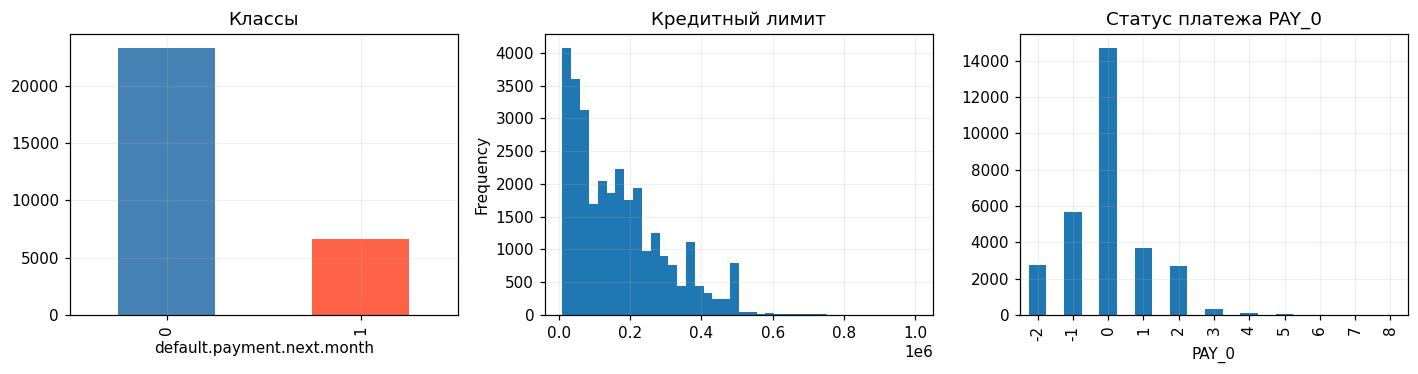

In [2]:
path = ROOT / "UCI_Credit_Card.csv"
if not path.exists():
    response = requests.get(URL, headers={"User-Agent": "kaggle-api/1.7.4"}, timeout=90)
    response.raise_for_status()
    path.write_bytes(zipfile.ZipFile(io.BytesIO(response.content)).read("UCI_Credit_Card.csv"))
df = pd.read_csv(path)
features = [c for c in df.columns if c not in ["ID", TARGET]]
categorical = ["SEX", "EDUCATION", "MARRIAGE"]
numeric = [c for c in features if c not in categorical]
X, y = df[features].copy(), df[TARGET].astype(int)
X[categorical] = X[categorical].astype(int)
groups = pd.util.hash_pandas_object(X, index=False).to_numpy()
assert set(y.unique()) == {0, 1} and X.notna().all().all() and np.isfinite(X.to_numpy()).all()
assert df.ID.is_unique
provenance = {"source": SOURCE, "download_url": URL, "sha256": hashlib.sha256(path.read_bytes()).hexdigest(), "rows": len(df), "author": "I-Cheng Yeh", "original_source": "https://doi.org/10.24432/C55S3H", "license": "CC BY 4.0"}
(ROOT / "data_provenance.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")
print("Размер:", df.shape, "Пропуски:", int(df.isna().sum().sum()), "Повторы профиля:", int(X.duplicated().sum()))
display(pd.DataFrame({"тип": df.dtypes.astype(str), "пропуски": df.isna().sum(), "уникальных": df.nunique()}))
display(X[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]].describe().T)
display(pd.DataFrame({c: X[c].value_counts().sort_index() for c in categorical}).fillna(0).astype(int))
display(y.value_counts().rename_axis("дефолт").to_frame("клиентов"))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
y.value_counts().sort_index().plot.bar(ax=axes[0], title="Классы", color=["steelblue", "tomato"])
X.LIMIT_BAL.plot.hist(bins=40, ax=axes[1], title="Кредитный лимит")
X.PAY_0.value_counts().sort_index().plot.bar(ax=axes[2], title="Статус платежа PAY_0")
plt.tight_layout(); plt.savefig(ROOT / "data_overview.png"); plt.show()

## Разбиение и сравнение
Около 20% групп откладывается в тест до подбора параметров. Внутри development используются пять одинаковых стратифицированных групповых фолдов. Это проверка переноса на других клиентов той же исторической выборки, а не временной backtest: порядковый ID не считается датой.

Сравниваются константа, LogisticRegression и три конфигурации CatBoost. Основная метрика выбора — ROC-AUC; дополнительно AP, поскольку дефолт — меньшинство. AP здесь означает average precision, а не трапецеидальную площадь PR-кривой. Масштабирование и one-hot у LogisticRegression обучаются внутри каждого фолда. CatBoost получает категории отдельно. Классы не ресэмплируются: оцениваем исходное распределение риска.

Каждый вариант создаёт отдельный MLflow run с параметрами и метриками фолдов. Лучший вариант выбирается только по среднему CV ROC-AUC. Порог классификации подбирается по F1 на его out-of-fold прогнозах development; это учебный критерий, а не банковская функция стоимости.

In [3]:
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED).split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups = groups[train_idx]
assert not set(train_groups) & set(groups[test_idx])
cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train, train_groups))
for a, b in cv:
    assert not set(train_groups[a]) & set(train_groups[b])
split = pd.DataFrame({"ID": df.ID, "split": "test", "fold": -1})
split.loc[train_idx, "split"] = "development"
for fold, (_, valid) in enumerate(cv):
    split.loc[train_idx[valid], "fold"] = fold
split.to_csv(ROOT / "split.csv", index=False)
display(pd.DataFrame({"n": [len(y_train), len(y_test)], "default_rate": [y_train.mean(), y_test.mean()]}, index=["development", "test"]))
preprocess = ColumnTransformer([("numeric", StandardScaler(), numeric), ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)])
candidates = {"constant": DummyClassifier(strategy="prior"), "logistic": make_pipeline(preprocess, LogisticRegression(max_iter=2000, random_state=SEED))}
for depth, learning_rate in [(4, .05), (6, .05), (6, .1)]:
    candidates[f"catboost_d{depth}_lr{learning_rate}"] = CatBoostClassifier(iterations=250, depth=depth, learning_rate=learning_rate, loss_function="Logloss", cat_features=categorical, random_seed=SEED, thread_count=4, allow_writing_files=False, verbose=False)
mlflow.set_tracking_uri("sqlite:///" + (ROOT / "mlflow.db").as_posix())
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(ROOT / "mlartifacts").as_uri())
mlflow.set_experiment(EXPERIMENT)
rows, oof_predictions = [], {}
for name, candidate in candidates.items():
    fold_metrics, oof = [], np.zeros(len(y_train))
    with mlflow.start_run(run_name=name):
        mlflow.log_params({"model": name, "seed": SEED, "folds": 5, "split": "StratifiedGroupKFold", "data_sha256": provenance["sha256"]})
        if isinstance(candidate, CatBoostClassifier):
            mlflow.log_params({k: candidate.get_params()[k] for k in ["iterations", "depth", "learning_rate"]})
        for fold, (a, b) in enumerate(cv):
            model = clone(candidate).fit(X_train.iloc[a], y_train.iloc[a])
            p = model.predict_proba(X_train.iloc[b])[:, 1]
            oof[b] = p
            metrics = {"roc_auc": roc_auc_score(y_train.iloc[b], p), "average_precision": average_precision_score(y_train.iloc[b], p), "log_loss": log_loss(y_train.iloc[b], p)}
            mlflow.log_metrics(metrics, step=fold)
            fold_metrics.append(metrics)
        scores = pd.DataFrame(fold_metrics)
        summary = {"cv_roc_auc": scores.roc_auc.mean(), "cv_roc_auc_std": scores.roc_auc.std(ddof=0), "cv_average_precision": scores.average_precision.mean(), "cv_log_loss": scores.log_loss.mean()}
        mlflow.log_metrics(summary)
        mlflow.log_artifact(str(ROOT / "data_provenance.json"))
        rows.append({"model": name, **summary, "run_id": mlflow.active_run().info.run_id})
        oof_predictions[name] = oof
        print(name, summary)
results = pd.DataFrame(rows).sort_values("cv_roc_auc", ascending=False)
results.to_csv(ROOT / "cv_results.csv", index=False)
display(results.drop(columns="run_id").round(5))
best_name = results.iloc[0]["model"]
precision, recall, thresholds = precision_recall_curve(y_train, oof_predictions[best_name])
f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
threshold = float(thresholds[np.argmax(f1)])
print("Выбран:", best_name, "Порог по OOF:", threshold)

,n,default_rate
development,23999,0.220551
test,6001,0.223796


2026/11/21 16:15:23 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/21 16:15:23 INFO mlflow.store.db.utils: Updating database tables


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step


... (33 outputs left out)

catboost_d6_lr0.05 {'cv_roc_auc': 0.7838630706407154, 'cv_roc_auc_std': 0.005388481338125159, 'cv_average_precision': 0.5575572913977834, 'cv_log_loss': 0.42607303808726577}


catboost_d6_lr0.1 {'cv_roc_auc': 0.7809022471827529, 'cv_roc_auc_std': 0.006018487109798885, 'cv_average_precision': 0.5532716677891087, 'cv_log_loss': 0.4287836041879089}


,model,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_log_loss
3,catboost_d6_lr0.05,0.78386,0.00539,0.55756,0.42607
2,catboost_d4_lr0.05,0.78274,0.00548,0.55468,0.42676
4,catboost_d6_lr0.1,0.78090,0.00602,0.55327,0.42878
1,logistic,0.72352,0.01031,0.50311,0.46518
0,constant,0.50000,0.00000,0.22055,0.52765


Выбран: catboost_d6_lr0.05 Порог по OOF: 0.2627572963736171


## Независимый тест и сохранение
Выбранная конфигурация обучается на всём development. Тест не используется для выбора модели или порога. Gini рассчитывается как 2 × ROC-AUC − 1; Brier и LogLoss оценивают вероятностный прогноз. Константный риск из development даёт ориентир для вероятностных метрик. Разброс пяти CV-оценок не является доверительным интервалом.

Сохраняются модель, порядок признаков, порог, разбиение и окружение. Отдельно проверяется совпадение прогнозов после загрузки joblib и MLflow-модели.

,roc_auc,average_precision,log_loss,brier,gini,precision,recall,f1,accuracy
constant,0.50000,0.22380,0.53170,0.17372,NaN,NaN,NaN,NaN,NaN
catboost_d6_lr0.05,0.78176,0.56416,0.42933,0.13445,0.56353,0.51813,0.58526,0.54965,0.78537


,прогноз 0,прогноз 1
нет дефолта,3927,731
дефолт,557,786


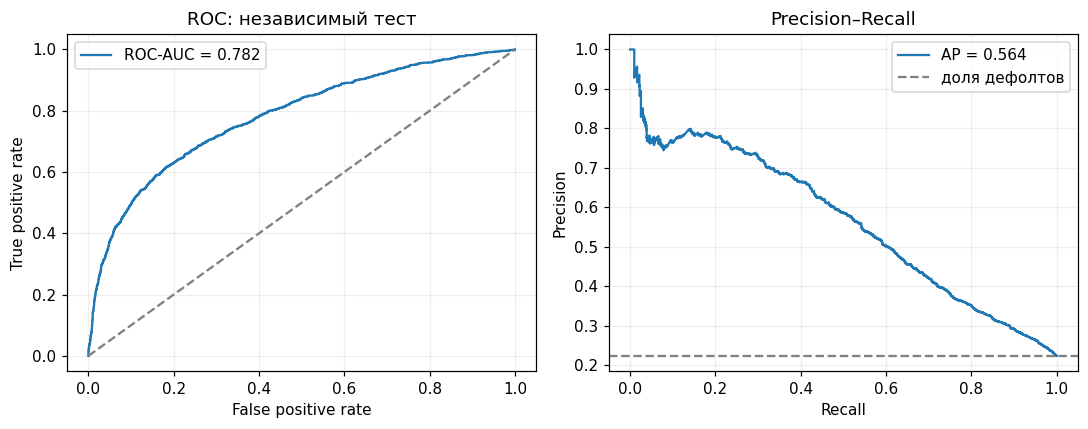

F:\Magistracy2_1\MLOps\Контрольная_1\.venv\lib\site-packages\mlflow\types\utils.py:407: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Выбрана **catboost_d6_lr0.05**: CV ROC-AUC **0.7839**, тест ROC-AUC **0.7818**, AP **0.5642** при доле дефолтов **22.38%**. При пороге **0.2628** precision = **0.5181**, recall = **0.5853**, F1 = **0.5497**. Матрица ошибок показывает цену выбранного компромисса. Восстановленные модели совпали по вероятностям на всех **6001** тестовых клиентах.

In [4]:
selected = clone(candidates[best_name]).fit(X_train, y_train)
p = selected.predict_proba(X_test)[:, 1]
pred = (p >= threshold).astype(int)
metrics = {"roc_auc": roc_auc_score(y_test, p), "gini": 2 * roc_auc_score(y_test, p) - 1, "average_precision": average_precision_score(y_test, p), "log_loss": log_loss(y_test, p), "brier": brier_score_loss(y_test, p), "precision": precision_score(y_test, pred, zero_division=0), "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred), "accuracy": accuracy_score(y_test, pred)}
constant = np.full(len(y_test), y_train.mean())
baseline = {"roc_auc": .5, "average_precision": average_precision_score(y_test, constant), "log_loss": log_loss(y_test, constant), "brier": brier_score_loss(y_test, constant)}
display(pd.DataFrame([baseline, metrics], index=["constant", best_name]).round(5))
cm = confusion_matrix(y_test, pred)
display(pd.DataFrame(cm, index=["нет дефолта", "дефолт"], columns=["прогноз 0", "прогноз 1"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fpr, tpr, _ = roc_curve(y_test, p)
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {metrics['roc_auc']:.3f}"); axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC: независимый тест"); axes[0].legend()
pr, re, _ = precision_recall_curve(y_test, p)
axes[1].plot(re, pr, label=f"AP = {metrics['average_precision']:.3f}"); axes[1].axhline(y_test.mean(), ls="--", color="grey", label="доля дефолтов")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall"); axes[1].legend()
plt.tight_layout(); plt.savefig(ROOT / "test_curves.png"); plt.show()
joblib.dump(selected, ROOT / "model.joblib")
context = {"model": best_name, "source": SOURCE, "features": features, "categorical": categorical, "target": TARGET, "threshold": threshold, "threshold_rule": "maximum F1 on development OOF", "seed": SEED, "development_size": len(y_train), "test_size": len(y_test), "development_default_rate": float(y_train.mean()), "test_default_rate": float(y_test.mean()), "cv_roc_auc": float(results.iloc[0].cv_roc_auc), "test": metrics, "confusion_matrix": cm.tolist(), "libraries": {k: version(k) for k in ["numpy", "pandas", "scikit-learn", "catboost", "mlflow"]}}
(ROOT / "model_context.json").write_text(json.dumps(context, ensure_ascii=False, indent=2), encoding="utf-8")
integer_fields = categorical + ["AGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
example = {c: int(v) if c in integer_fields else float(v) for c, v in X_test.iloc[0].items()}
(ROOT / "example.json").write_text(json.dumps(example, ensure_ascii=False, indent=2), encoding="utf-8")
signature = infer_signature(X_train, selected.predict_proba(X_train))
with mlflow.start_run(run_name="selected_model_test"):
    mlflow.log_params({"selected_model": best_name, "threshold": threshold, "threshold_selection": "development OOF F1", "seed": SEED})
    mlflow.log_metrics({"test_" + k: v for k, v in metrics.items()})
    if isinstance(selected, CatBoostClassifier):
        mlflow.catboost.log_model(selected, artifact_path="model", signature=signature, input_example=X_train.head(2))
        reload_model = mlflow.catboost.load_model
    else:
        mlflow.sklearn.log_model(selected, artifact_path="model", signature=signature, input_example=X_train.head(2))
        reload_model = mlflow.sklearn.load_model
    for filename in ["model_context.json", "data_provenance.json", "split.csv", "cv_results.csv", "test_curves.png"]:
        mlflow.log_artifact(str(ROOT / filename))
    run_id = mlflow.active_run().info.run_id
restored = joblib.load(ROOT / "model.joblib")
tracked = reload_model(f"runs:/{run_id}/model")
joblib_error = float(np.max(np.abs(p - restored.predict_proba(X_test)[:, 1])))
mlflow_error = float(np.max(np.abs(p - tracked.predict_proba(X_test)[:, 1])))
assert joblib_error < 1e-12 and mlflow_error < 1e-12
verification = {"test_rows": len(X_test), "joblib_max_probability_difference": joblib_error, "mlflow_max_probability_difference": mlflow_error, "selected_run_id": run_id, "group_overlap_train_test": 0}
(ROOT / "verification.json").write_text(json.dumps(verification, indent=2), encoding="utf-8")
display(Markdown(f"Выбрана **{best_name}**: CV ROC-AUC **{context['cv_roc_auc']:.4f}**, тест ROC-AUC **{metrics['roc_auc']:.4f}**, AP **{metrics['average_precision']:.4f}** при доле дефолтов **{y_test.mean():.2%}**. При пороге **{threshold:.4f}** precision = **{metrics['precision']:.4f}**, recall = **{metrics['recall']:.4f}**, F1 = **{metrics['f1']:.4f}**. Матрица ошибок показывает цену выбранного компромисса. Восстановленные модели совпали по вероятностям на всех **{len(X_test)}** тестовых клиентах."))

## Связь с курсом и вывод
В лекции 15.09.2026, слайды 9–15, рассматриваются подготовка данных, перебор параметров, запись метрик, выпуск модели и мониторинг. Здесь эти этапы связаны одним сохранённым артефактом. В материале MLflow, выданном 07.11, [пример преподавателя](https://github.com/mtpatter/mlflow-tutorial) показывает Tracking API и сохранение модели. Конкретный датасет, группировка повторов, CatBoost и критерий порога — адаптация к нашей задаче, а не код из лекции.

По сравнению с ДЗ 1.1 сохранены предметная область дефолта, baseline, CatBoost и оценка ROC-AUC/AP. Добавлены учёт запусков в MLflow и выпуск модели в API. Исходные транзакционные агрегаты Alfa-Battle сюда не переносятся: новый набор уже содержит месячные показатели. Групповая проверка отвечает структуре этих данных; временная проверка из прошлого ДЗ не имитируется по произвольному ID.

Для №47 модель и контекст загружает FastAPI в Docker. Для №49 сначала выполняются ячейки обучения; команда `python -m mlflow ui --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5051` только показывает результаты. В этой работе нет файла MLproject; `mlflow run .` используется для отдельно оформленных MLflow Projects.

Числа выше относятся к выполненному тесту. Вероятность не объявляется откалиброванной для реального банка; порог F1 не учитывает стоимость выдачи кредита, fairness и сдвиг популяции. Мониторинг и Kubernetes-развёртывание в этой практике не выполнялись.